In [1]:
import numpy as np
from scipy.linalg import block_diag
from utils import plot_car_estimation, rmse, observable
from typing import Optional

# Define process and measurement noises
Q = np.diag([0.0, 0.01, 0.0]) # process noise
std_imu = 0.25
std_gnss = 5.0
std_lidar = 5.0

In [2]:
def simulate(
    x0: np.ndarray, 
    u: np.ndarray, 
    A: np.ndarray, 
    B: np.ndarray, 
    C: np.ndarray, 
    Q: np.ndarray, 
    R: np.ndarray, 
    mean0: np.ndarray, 
    cov0: np.ndarray, 
    num_sims: int, 
    bias: Optional[np.ndarray]=None,
) -> tuple[np.ndarray, np.ndarray, float]:
    """
    Simulate the linear system and KF estimation. Compute RSME
    to estimate error of the filter across time and over a batch of runs.

    Args:
        x0: initial state of the system, shape (n,)
        u: controls to apply at each time step, shape (m, N)
        A: dynamics matrix, shape (n, n)
        B: control matrix, shape (n, m)
        C: measurement matrix, shape (o, n)
        Q: process noise covariance, shape (n, n)
        R: measurement noise covariance, shape (o, o)
        mean0: initial KF mean, shape (n,)
        cov0: initial KF covariance, shape (n, n)
        num_sims: number of simulations to batch for RMSE calc
        bias: bias to the measurement, or None to not add a bias

    Returns:
        Actual state trajectory from the last batch run, shape (n, N + 1).
        KF mean estimate trajectory from the last batch, shape (n, N + 1).
        Average RMSE over the batch of runs.
    """
    total_pos_rmse = 0
    for run in range(num_sims):
        n = x0.size
        o = C.shape[0]
        N = u.shape[1]
        x = np.zeros((n, N + 1))
        x[:, 0] = x0
        mean = np.zeros((n, N + 1))
        mean[:, 0] = mean0
        cov = cov0
        rng = np.random.default_rng(run) # for determinism
        for i in range(N):
            # Simulate dynamics
            ϵ = rng.multivariate_normal(np.zeros((Q.shape[0],)), Q)
            x[:, i + 1] = A @ x[:, i] + B @ u[:, i] + ϵ
        
            # Simulate measurement
            δ = rng.multivariate_normal(np.zeros((R.shape[0],)), R)
            b = np.zeros(o) if bias is None else bias
            z = C @ x[:, i] + b + δ
        
            # Estimation
            mean[:, i + 1], cov = kalman_filter_update(A, B, C, Q, R, mean[:, i], cov, u[:, i], z)

        # Position error metric
        total_pos_rmse += rmse(x[0, :], mean[0, :])
    return x, mean, total_pos_rmse / num_sims

In [3]:
T = 0.01 # sampling time
##### YOUR CODE STARTS HERE #####
# Longitudinal car dynamics model (discrete time)
A = np.array([[1.0, T, 0.5 * T**2],
              [0.0, 1.0, T],
              [0.0, 0.0, 1.0]])
B = np.array([
            [(1.0/6.0) * T**3],
            [0.5* T**2],
            [T] ])

###### YOUR CODE ENDS HERE ######

In [4]:
def kalman_filter_update(
    A: np.ndarray, 
    B: np.ndarray, 
    C: np.ndarray, 
    Q: np.ndarray, 
    R: np.ndarray, 
    mean: np.ndarray, 
    cov: np.ndarray, 
    u: np.ndarray, 
    z: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Kalman filter update step.

    Args:
        A: dynamics matrix, shape (n, n)
        B: control matrix, shape (n, m)
        C: measurement matrix, shape (o, n)
        Q: process noise covariance, shape (n, n)
        R: measurement noise covariance, shape (o, o)
        mean: mean estimate, shape (n,)
        cov: estimate covariance, shape (n, n)
        u: control input, shape (m,)
        z: measurement, shape (o,)

    Returns:
        Posterior mean and covariance.
    """
    ##### YOUR CODE STARTS HERE #####
    # NOTE: Implement Kalman Filtering Predict and Update steps.
    # Write resulting means to mean.
    # Write resulting covariances to cov.
    # 1. Predict step
    mean_pred = A @ mean + B @ u
    cov_pred = A @ cov @ A.T + Q
    # 2. Update step
    innovation = z - C @ mean_pred
    S = C @ cov_pred @ C.T + R
    K = cov_pred @ C.T @ np.linalg.inv(S)

    mean = mean_pred + K @ innovation
    I = np.eye(A.shape[0])
    cov = (I - K @ C) @ cov_pred
    ###### YOUR CODE ENDS HERE ######
    return mean, cov

State is observable with sensor config: False
Position RMSE: 33.000


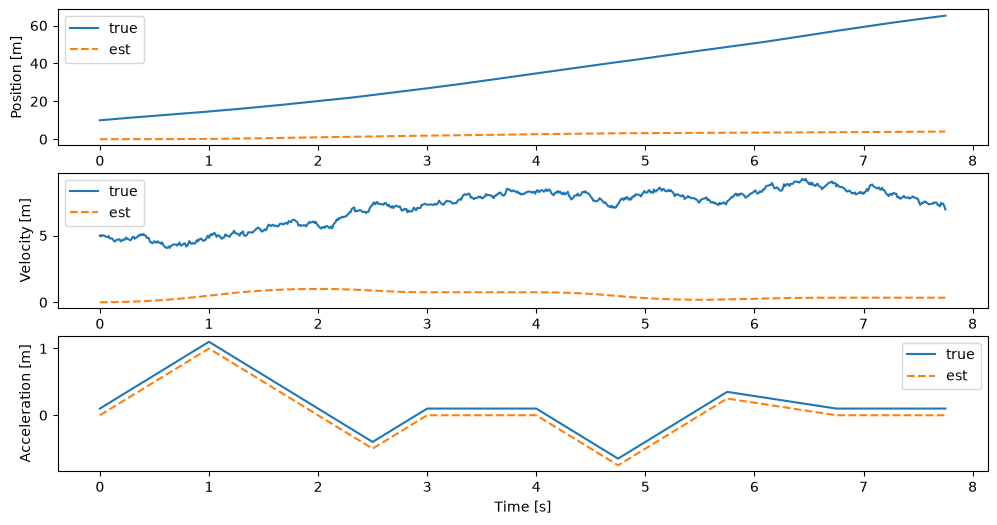

In [16]:
# Form an interesting jerk input sequence
u = np.hstack([np.ones(100), -1*np.ones(150), np.ones(50), np.zeros(100), -np.ones(75), np.ones(100), -0.25*np.ones(100), np.zeros(100)])
u = u.reshape((1, u.size))

# Assume we don't know the exact initial condition
x0 = np.array([10, 5, 0.1])

# First run a case where we have no measurements to see the error
C = np.array([[0, 0, 0]])
R = np.diag([1])

# Simulate
num_sims = 10
mean0 = np.zeros(3) #start = 0
cov0 = np.diag([100.0, 10.0, 1.0]) #tại sao là 100 10 1 mà k phải 1 1 1
# cov0 = np.diag([1.0, 1.0, 1.0])
x, mean, p_error_none = simulate(x0, u, A, B, C, Q, R, mean0, cov0, num_sims)
print(f"State is observable with sensor config: {observable(A, C)}")

# Compute RMSE for position
print(f"Position RMSE: {p_error_none:.3f}")

# Plot to see accuracy
plot_car_estimation(x, mean, T)

State is observable with sensor config: False
IMU Position RMSE: 32.289
RMSE change compared to no sensors: -2.16%


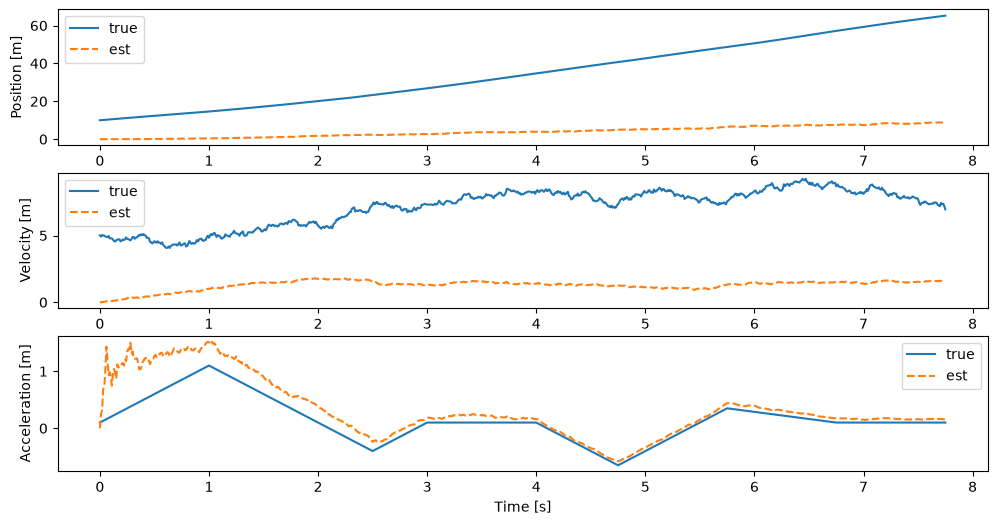

In [17]:
##### YOUR CODE STARTS HERE #####
# Define measurement model for IMU only
C = np.array([[0.0, 0.0, 0.1]])
R = np.diag([std_imu**2])
###### YOUR CODE ENDS HERE ######

# Simulate
x, mean, p_error_imu = simulate(x0, u, A, B, C, Q, R, mean0, cov0, num_sims)
print(f"State is observable with sensor config: {observable(A, C)}")

# Compute RMSE for position
improvement = 100*(p_error_imu - p_error_none) / p_error_none
print(f"IMU Position RMSE: {p_error_imu:.3f}")
print(f"RMSE change compared to no sensors: {improvement:.2f}%")

# Plot to see accuracy
plot_car_estimation(x, mean, T)

State is observable with sensor config: True
IMU + lidar Position RMSE: 0.940
RMSE change compared to no sensors: -97.15%


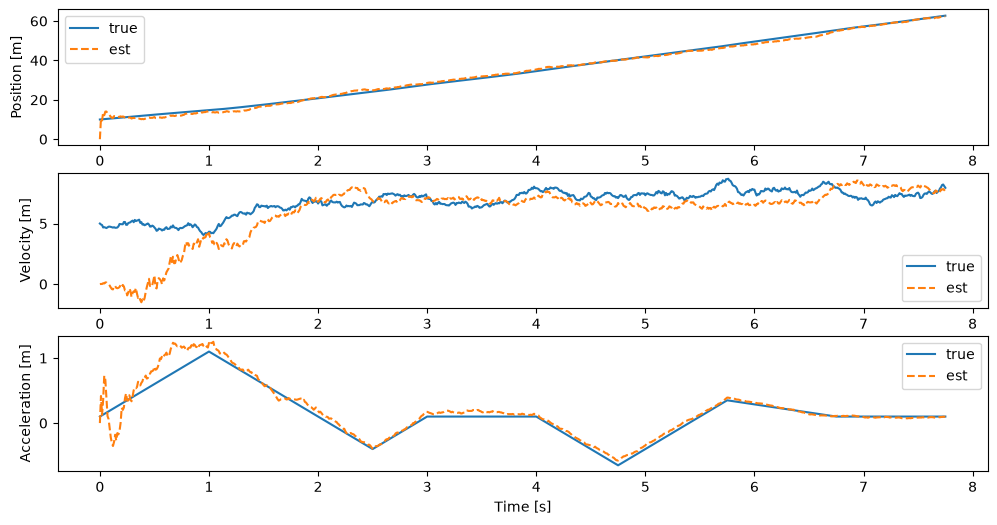

In [18]:
##### YOUR CODE STARTS HERE #####
# Define measurement model for IMU + lidar
C = np.array([[0.0, 0.0, 0.1],
             [1.0, 0.0, 0.0]])
R = np.diag([std_imu**2, std_lidar**2])
###### YOUR CODE ENDS HERE ######

# Simulate
x, mean, p_error_imu_lidar = simulate(x0, u, A, B, C, Q, R, mean0, cov0, num_sims)
print(f"State is observable with sensor config: {observable(A, C)}")

# Compute RMSE for position
improvement = 100*(p_error_imu_lidar - p_error_none) / p_error_none
print(f"IMU + lidar Position RMSE: {p_error_imu_lidar:.3f}")
print(f"RMSE change compared to no sensors: {improvement:.2f}%")

# Plot to see accuracy
plot_car_estimation(x, mean, T)

State is observable with sensor config: True
IMU + lidar + GNSS Position RMSE: 0.720
RMSE change compared to no sensors: -97.82%
RMSE change compared to IMU + lidar: -23.37%


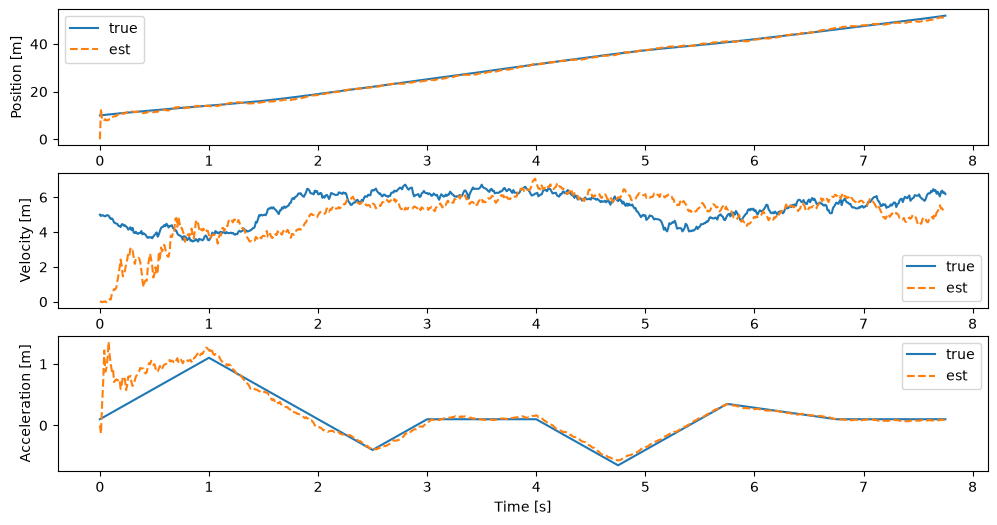

In [19]:
##### YOUR CODE STARTS HERE #####
# Define measurement model for IMU + lidar + GNSS with bias
C = np.array([ [0.0, 0.0, 0.1],
                [1.0, 0.0, 0.0],
                 [1.0, 0.0, 0.0]])
R = np.diag([std_imu**2, std_lidar**2, std_gnss**2])
###### YOUR CODE ENDS HERE ######

# GNSS bias
gnss_bias = 10.0
bias = np.array([0, 0, gnss_bias]) 

# Simulate
# x, mean, p_error_imu_lidar_gnss = simulate(x0, u, A, B, C, Q, R, mean0, cov0, num_sims, bias)
x, mean, p_error_imu_lidar_gnss = simulate(x0, u, A, B, C, Q, R, mean0, cov0, num_sims)
print(f"State is observable with sensor config: {observable(A, C)}")

# Compute RMSE for position
improvement = 100*(p_error_imu_lidar_gnss - p_error_none) / p_error_none
improvement_lidar_only = 100*(p_error_imu_lidar_gnss - p_error_imu_lidar) / p_error_imu_lidar
print(f"IMU + lidar + GNSS Position RMSE: {p_error_imu_lidar_gnss:.3f}")
print(f"RMSE change compared to no sensors: {improvement:.2f}%")
print(f"RMSE change compared to IMU + lidar: {improvement_lidar_only:.2f}%")

# Plot to see accuracy
plot_car_estimation(x, mean, T)

State + bias is observable with sensor config: True
IMU + lidar + augmented GNSS Position RMSE: 0.917
RMSE change compared to no sensors: -97.22%
RMSE change compared to IMU + lidar: -2.49%
RMSE change compared to IMU + lidar + (non-augmented) GNSS: 27.25%


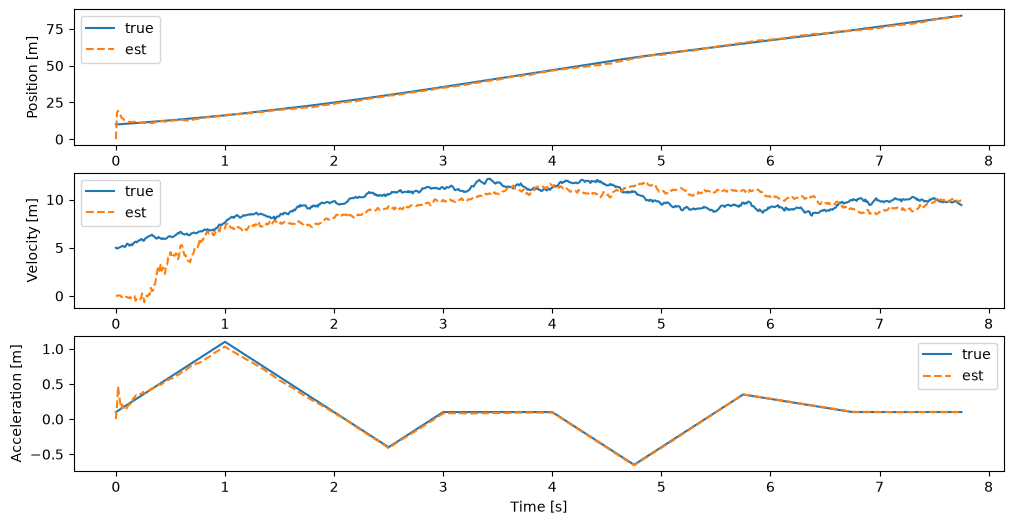

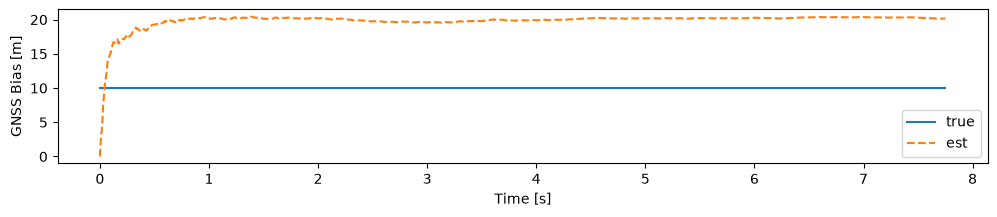

In [20]:
##### YOUR CODE STARTS HERE #####
# Define augmented state system
A_aug = block_diag(A, 1.0)
B_aug = np.vstack((B, [[0.0]]))
Q_aug = block_diag(Q, 0.0)
C_aug = np.array([
    [0.0, 0.0, 1.0, 0.0],
    [1.0, 0.0, 0.0, 0.0],
    [1.0, 0.0, 0.0, 1.0]
])
R_aug = np.diag([std_imu**2, std_lidar**2, std_gnss**2])
R = R_aug
###### YOUR CODE ENDS HERE ######

# Simulate
x0_aug = np.hstack((x0, gnss_bias))
mean0_aug = np.hstack((mean0, 0))
cov0_aug = block_diag(cov0, 10)
x, mean, p_error_imu_lidar_aug_gnss = simulate(x0_aug, u, A_aug, B_aug, C_aug, Q_aug, R, mean0_aug, cov0_aug, num_sims, bias)
print(f"State + bias is observable with sensor config: {observable(A_aug, C_aug)}")

# Compute RMSE for position
improvement = 100*(p_error_imu_lidar_aug_gnss - p_error_none) / p_error_none
improvement_lidar_only = 100*(p_error_imu_lidar_aug_gnss - p_error_imu_lidar) / p_error_imu_lidar
improvement_lidar_bias_gnss = 100*(p_error_imu_lidar_aug_gnss - p_error_imu_lidar_gnss) / p_error_imu_lidar_gnss
print(f"IMU + lidar + augmented GNSS Position RMSE: {p_error_imu_lidar_aug_gnss:.3f}")
print(f"RMSE change compared to no sensors: {improvement:.2f}%")
print(f"RMSE change compared to IMU + lidar: {improvement_lidar_only:.2f}%")
print(f"RMSE change compared to IMU + lidar + (non-augmented) GNSS: {improvement_lidar_bias_gnss:.2f}%")

# Plot to see accuracy
plot_car_estimation(x, mean, T)